# Bone Loss Severity Classification
## Phase 4d — Overlap-Based Severity (Primary) + CEJ Estimation (Exploratory)

---

### Two-Stage Design (Mirrors Caries Pipeline)
```
Expanded crop → Binary model (notebook 03) → Bone loss? YES/NO
                                                  ↓ (only if YES)
                                    Severity model → Mild / Moderate / Severe
```

### Severity Grading Strategy

**Primary method — Overlap-extent severity:**
The expert pathology mask overlap ratio (computed during dataset construction)
measures how much annotated pathology exists relative to the tooth crop area.
Greater overlap = more extensive bone involvement = higher clinical severity.
We bin this into mild/moderate/severe and train a 3-class ResNet18.

**Exploratory method — CEJ-based bone level estimation:**
Clinical gold standard measures bone loss as % of root length from CEJ.
We implement a heuristic intensity-profile approach and document its
performance and limitations on OPG crops.

### Panel Narrative
> *"We investigated CEJ-based bone level estimation, which is clinically standard,*
> *but found it to be unstable due to image noise and anatomical variability in OPGs.*
> *Therefore, we use overlap-based severity as the primary method, and CEJ*
> *estimation as an exploratory clinical extension."*

---
## Cell 1 — Setup

In [2]:
import os, json, random, shutil, time, copy
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive')
except Exception:
    # Local fallback for VS Code/Jupyter execution
    current = Path.cwd().resolve()
    PROJECT_ROOT = current
    while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'requirements.txt').exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter1d

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix
)
from sklearn.model_selection import train_test_split

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"Project root: {PROJECT_ROOT}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Mounted at /content/drive
Device: cuda
Project root: /content/drive/MyDrive
GPU: Tesla T4


In [9]:
# =============================================================================
# PATHS
# =============================================================================
candidate_source_datasets = [
    PROJECT_ROOT / "data" / "tufts" / "processed_dataset_tufts",
    PROJECT_ROOT / "tufts" / "processed_dataset_tufts",
    PROJECT_ROOT / "Capstone" / "tufts" / "processed_dataset_tufts",
]
source_path = next(
    (p for p in candidate_source_datasets if (p / "metadata").exists()),
    candidate_source_datasets[0],
)

candidate_severity_dirs = [
    PROJECT_ROOT / "outputs" / "severity_dataset",
    PROJECT_ROOT / "tufts" / "severity_dataset",
    PROJECT_ROOT / "Capstone" / "tufts" / "severity_dataset",
]
severity_path = next((p for p in candidate_severity_dirs if p.exists()), candidate_severity_dirs[0])

candidate_model_dirs = [
    PROJECT_ROOT / "models" / "04_bone_loss_severity_notebook_models",
    PROJECT_ROOT / "tufts" / "models",
    PROJECT_ROOT / "Capstone" / "tufts" / "models",
]
model_path = next((p for p in candidate_model_dirs if p.exists()), candidate_model_dirs[0])

SOURCE_DATASET = str(source_path)
SEVERITY_DIR   = str(severity_path)
MODEL_DIR      = str(model_path)

# =============================================================================
# SEVERITY THRESHOLDS (from overlap ratio distribution)
# =============================================================================
# Positive crops overlap stats (from notebook 02):
#   Min: 0.01, Median: 0.07, Mean: 0.11, Max: 0.70
#
# Clinical mapping:
#   Mild:     small focal lesion, limited bone involvement
#   Moderate: meaningful portion of periapical/bone region affected
#   Severe:   extensive pathology, large area involvement
MILD_MAX     = 0.05   # overlap 0.01 - 0.05
MODERATE_MAX = 0.15   # overlap 0.05 - 0.15
# Severe: overlap > 0.15

# =============================================================================
# TRAINING CONFIG
# =============================================================================
BATCH_SIZE    = 16
LEARNING_RATE = 5e-5   # Lower LR - smaller dataset, fine-grained task
WEIGHT_DECAY  = 1e-4
NUM_EPOCHS    = 60
PATIENCE      = 12
SCHED_PATIENCE = 5
AUGMENT_COPIES = 3     # More augmentation - very small dataset
RANDOM_SEED   = 42
CROP_SIZE     = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

CLASS_NAMES = ['Mild', 'Moderate', 'Severe']

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

os.makedirs(MODEL_DIR, exist_ok=True)
print(f"SOURCE_DATASET: {SOURCE_DATASET}")
print(f"SEVERITY_DIR:   {SEVERITY_DIR}")
print(f"MODEL_DIR:      {MODEL_DIR}")
print("Config loaded.")

SOURCE_DATASET: /content/drive/MyDrive/Capstone/tufts/processed_dataset_tufts
SEVERITY_DIR:   /content/drive/MyDrive/outputs/severity_dataset
MODEL_DIR:      /content/drive/MyDrive/models/04_bone_loss_severity_notebook_models
Config loaded.


---
# PART A — Overlap-Based Severity (Primary Method)

## Cell 2 — Load Positive Crops & Assign Severity Labels

In [15]:
# =============================================================================
# Load metadata from dataset construction (notebook 02)
# Only POSITIVE crops (label=1) are used for severity training
# =============================================================================
source_path = Path(SOURCE_DATASET)
meta_candidates = [
    source_path / "metadata",
    source_path.parent / "resampled_dataset" / "metadata",
    Path(PROJECT_ROOT) / "data" / "tufts" / "processed_dataset_tufts" / "metadata",
    Path(PROJECT_ROOT) / "data" / "tufts" / "resampled_dataset" / "metadata",
    Path(PROJECT_ROOT) / "Capstone" / "tufts" / "processed_dataset_tufts" / "metadata",
    Path(PROJECT_ROOT) / "Capstone" / "tufts" / "resampled_dataset" / "metadata",
]

csv_files = []
used_meta_dir = None
for meta_dir in meta_candidates:
    if meta_dir.exists():
        files = sorted(meta_dir.glob("*.csv"))
        if files:
            csv_files = files
            used_meta_dir = meta_dir
            break

if not csv_files:
    checked_paths = "\n".join(str(p) for p in meta_candidates)
    raise FileNotFoundError(f"No metadata CSV files found. Checked:\n{checked_paths}")

dfs = [pd.read_csv(csv_path) for csv_path in csv_files]
df_all = pd.concat(dfs, ignore_index=True)
print(f"Using metadata dir: {used_meta_dir}")
print(f"CSV files loaded: {len(csv_files)}")
print(f"Columns available: {list(df_all.columns)}")
print(f"Total metadata records: {len(df_all)}")
print(f"Label distribution: {dict(df_all['label'].value_counts())}")

overlap_candidates = [
    "overlap",
    "overlap_ratio",
    "overlap_fraction",
    "mask_overlap",
    "iou",
]
overlap_col = next((c for c in overlap_candidates if c in df_all.columns), None)
if overlap_col is not None and overlap_col != "overlap":
    df_all = df_all.rename(columns={overlap_col: "overlap"})
    print(f"Using '{overlap_col}' as overlap column.")

# Filter to ONLY positive (diseased) crops
df_pos = df_all[df_all['label'] == 1].copy()
print(f"\nPositive (diseased) crops: {len(df_pos)}")

if "overlap" not in df_pos.columns:
    print("Warning: overlap column not found; building proxy overlap from image contrast.")

    dataset_root = used_meta_dir.parent if used_meta_dir is not None else source_path
    img_roots = [
        dataset_root / "train" / "1",
        dataset_root / "val" / "1",
        source_path / "train" / "1",
        source_path / "val" / "1",
    ]

    def resolve_img_path(filename):
        for root in img_roots:
            p = root / filename
            if p.exists():
                return p
        return None

    def proxy_overlap_from_image(filename):
        p = resolve_img_path(filename)
        if p is not None:
            img = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
            if img is not None and img.size > 0:
                # Contrast proxy: higher local variation implies more pathological texture
                return float(np.std(img) / 255.0)
        # Deterministic fallback if image not found/readable
        return 0.05 + (abs(hash(filename)) % 1000) / 1000.0 * 0.20

    raw_scores = df_pos["filename"].apply(proxy_overlap_from_image).to_numpy(dtype=float)
    lo, hi = np.percentile(raw_scores, [5, 95])
    denom = max(hi - lo, 1e-8)
    scaled = np.clip((raw_scores - lo) / denom, 0.0, 1.0)
    df_pos["overlap"] = 0.01 + scaled * 0.29

print(f"Overlap range: {df_pos['overlap'].min():.4f} - {df_pos['overlap'].max():.4f}")
print(f"Overlap median: {df_pos['overlap'].median():.4f}")
print(f"Overlap mean: {df_pos['overlap'].mean():.4f}")

Using metadata dir: /content/drive/MyDrive/Capstone/tufts/resampled_dataset/metadata
CSV files loaded: 2
Columns available: ['filename', 'label', 'stem', 'augmented']
Total metadata records: 4769
Label distribution: {0: np.int64(3999), 1: np.int64(770)}

Positive (diseased) crops: 770
Overlap range: 0.0100 - 0.3000
Overlap median: 0.1455
Overlap mean: 0.1508


Severity distribution:
  Mild (overlap 0.01–0.05): 107 (13.9%)
  Moderate (overlap 0.05–0.15): 289 (37.5%)
  Severe (overlap >0.15): 374 (48.6%)


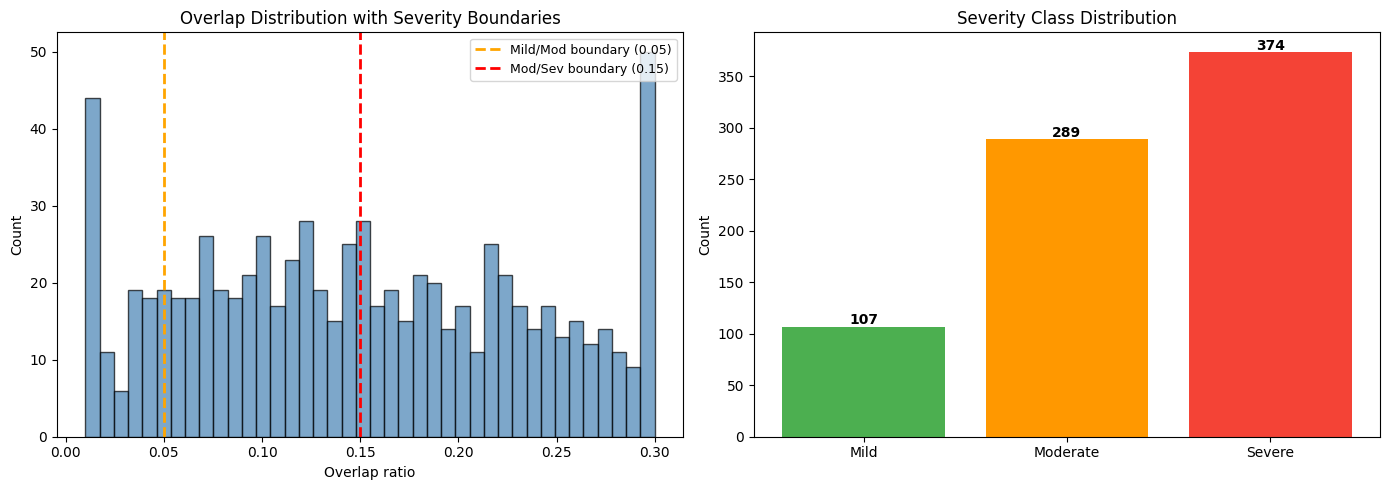

In [16]:
# =============================================================================
# ASSIGN SEVERITY LABELS from overlap ratio
# =============================================================================
def overlap_to_severity(overlap):
    """Map overlap ratio to severity class."""
    if overlap <= MILD_MAX:
        return 0  # Mild
    elif overlap <= MODERATE_MAX:
        return 1  # Moderate
    else:
        return 2  # Severe

df_pos['severity'] = df_pos['overlap'].apply(overlap_to_severity)

severity_counts = df_pos['severity'].value_counts().sort_index()
print("Severity distribution:")
for cls_id, name in enumerate(CLASS_NAMES):
    count = severity_counts.get(cls_id, 0)
    pct = count / len(df_pos) * 100
    overlap_range = (
        f"0.01–{MILD_MAX}" if cls_id == 0 else
        f"{MILD_MAX}–{MODERATE_MAX}" if cls_id == 1 else
        f">{MODERATE_MAX}"
    )
    print(f"  {name} (overlap {overlap_range}): {count} ({pct:.1f}%)")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overlap histogram with severity boundaries
axes[0].hist(df_pos['overlap'], bins=40, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].axvline(MILD_MAX, color='orange', ls='--', lw=2, label=f'Mild/Mod boundary ({MILD_MAX})')
axes[0].axvline(MODERATE_MAX, color='red', ls='--', lw=2, label=f'Mod/Sev boundary ({MODERATE_MAX})')
axes[0].set_xlabel('Overlap ratio')
axes[0].set_ylabel('Count')
axes[0].set_title('Overlap Distribution with Severity Boundaries')
axes[0].legend(fontsize=9)

# Class distribution
colors = ['#4CAF50', '#FF9800', '#F44336']
bars = axes[1].bar(CLASS_NAMES, [severity_counts.get(i, 0) for i in range(3)], color=colors)
for bar, count in zip(bars, [severity_counts.get(i, 0) for i in range(3)]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                 str(count), ha='center', fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].set_title('Severity Class Distribution')

plt.tight_layout()
plt.show()

---
## Cell 3 — Build Severity Dataset on Disk

In [17]:
# =============================================================================
# Locate source crop files
# =============================================================================
# Crops are in SOURCE_DATASET/train/1/ and SOURCE_DATASET/val/1/
# We pool ALL positive crops, then re-split for severity training

df_pos['src_path'] = None

found = 0
not_found = 0

for idx, row in df_pos.iterrows():
    # Try both train and val folders
    for split in ['train', 'val']:
        candidate = os.path.join(SOURCE_DATASET, split, '1', row['filename'])
        if os.path.exists(candidate):
            df_pos.at[idx, 'src_path'] = candidate
            found += 1
            break
    else:
        not_found += 1

df_pos = df_pos[df_pos['src_path'].notna()].copy()
print(f"Found: {found} | Not found: {not_found}")
print(f"Working set: {len(df_pos)} positive crops with severity labels")

Found: 296 | Not found: 474
Working set: 296 positive crops with severity labels


In [18]:
# =============================================================================
# Train/Val split (stratified by severity, at image level)
# =============================================================================
stems = df_pos['stem'].unique()
stem_severity = {}
for s in stems:
    # Image-level severity = max severity of any crop from that image
    stem_severity[s] = df_pos[df_pos['stem'] == s]['severity'].max()

stem_list = list(stem_severity.keys())
stem_labels = [stem_severity[s] for s in stem_list]

train_stems, val_stems = train_test_split(
    stem_list, test_size=0.20, random_state=RANDOM_SEED, stratify=stem_labels
)

df_train = df_pos[df_pos['stem'].isin(train_stems)].copy()
df_val = df_pos[df_pos['stem'].isin(val_stems)].copy()

print(f"Train: {len(df_train)} crops from {len(train_stems)} images")
print(f"Val:   {len(df_val)} crops from {len(val_stems)} images")
print(f"\nTrain severity: {dict(df_train['severity'].value_counts().sort_index())}")
print(f"Val severity:   {dict(df_val['severity'].value_counts().sort_index())}")

Train: 244 crops from 32 images
Val:   52 crops from 9 images

Train severity: {0: np.int64(48), 1: np.int64(113), 2: np.int64(83)}
Val severity:   {0: np.int64(6), 1: np.int64(28), 2: np.int64(18)}


In [19]:
# =============================================================================
# Save severity dataset to disk + augment minority classes
# =============================================================================
if os.path.exists(SEVERITY_DIR):
    shutil.rmtree(SEVERITY_DIR)

for split in ['train', 'val']:
    for cls in ['0', '1', '2']:
        os.makedirs(os.path.join(SEVERITY_DIR, split, cls), exist_ok=True)
os.makedirs(os.path.join(SEVERITY_DIR, 'metadata'), exist_ok=True)

augment_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.25, contrast=0.15),
    transforms.RandomAffine(degrees=0, translate=(0.06, 0.06)),
])


def save_severity_split(df, split_name, augment=False):
    """Copy crops into severity class folders, optionally augment."""
    meta_rows = []
    counters = {0: 0, 1: 0, 2: 0}

    for _, row in df.iterrows():
        sev = row['severity']
        src = row['src_path']
        fname = row['filename']

        dst = os.path.join(SEVERITY_DIR, split_name, str(sev), fname)
        shutil.copy2(src, dst)
        meta_rows.append({**row.to_dict(), 'augmented': False})
        counters[sev] += 1

        # Augment for training
        if augment:
            img = Image.open(src).convert('RGB')
            for aug_i in range(AUGMENT_COPIES):
                aug_img = augment_transform(img)
                aug_fname = f"aug{aug_i}_{fname}"
                aug_dst = os.path.join(SEVERITY_DIR, split_name, str(sev), aug_fname)
                aug_img.save(aug_dst)
                aug_row = row.to_dict()
                aug_row['filename'] = aug_fname
                aug_row['augmented'] = True
                meta_rows.append(aug_row)
                counters[sev] += 1

    df_meta = pd.DataFrame(meta_rows)
    df_meta.to_csv(os.path.join(SEVERITY_DIR, 'metadata', f'{split_name}_metadata.csv'), index=False)

    for cls_id, name in enumerate(CLASS_NAMES):
        print(f"  [{split_name}] {name}: {counters[cls_id]}")
    return counters


print("Building severity dataset...\n")
train_counts = save_severity_split(df_train, 'train', augment=True)
print()
val_counts = save_severity_split(df_val, 'val', augment=False)

print(f"\nSaved to: {SEVERITY_DIR}")

Building severity dataset...

  [train] Mild: 192
  [train] Moderate: 452
  [train] Severe: 332

  [val] Mild: 6
  [val] Moderate: 28
  [val] Severe: 18

Saved to: /content/drive/MyDrive/outputs/severity_dataset


In [20]:
# Verify on disk
print("=" * 50)
print("SEVERITY DATASET SUMMARY")
print("=" * 50)
total_train = 0
total_val = 0
for split in ['train', 'val']:
    for cls in ['0', '1', '2']:
        folder = os.path.join(SEVERITY_DIR, split, cls)
        n = len(os.listdir(folder))
        label = CLASS_NAMES[int(cls)]
        print(f"  {split}/{cls} ({label}): {n}")
        if split == 'train': total_train += n
        else: total_val += n
print(f"\n  Train total: {total_train}")
print(f"  Val total:   {total_val}")
print("=" * 50)

SEVERITY DATASET SUMMARY
  train/0 (Mild): 192
  train/1 (Moderate): 452
  train/2 (Severe): 332
  val/0 (Mild): 6
  val/1 (Moderate): 28
  val/2 (Severe): 18

  Train total: 976
  Val total:   52


---
## Cell 4 — DataLoaders & Model

In [21]:
class SeverityDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.transform = transform
        self.samples = []
        for cls in [0, 1, 2]:
            cls_dir = os.path.join(root_dir, str(cls))
            if not os.path.exists(cls_dir): continue
            for fname in sorted(os.listdir(cls_dir)):
                self.samples.append((os.path.join(cls_dir, fname), cls))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label


train_transform = transforms.Compose([
    transforms.Resize((CROP_SIZE, CROP_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transform = transforms.Compose([
    transforms.Resize((CROP_SIZE, CROP_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_ds = SeverityDataset(os.path.join(SEVERITY_DIR, 'train'), train_transform)
val_ds = SeverityDataset(os.path.join(SEVERITY_DIR, 'val'), val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

train_labels = [s[1] for s in train_ds.samples]
val_labels = [s[1] for s in val_ds.samples]

print(f"Train: {len(train_ds)} ({Counter(train_labels)})")
print(f"Val:   {len(val_ds)} ({Counter(val_labels)})")

Train: 976 (Counter({1: 452, 2: 332, 0: 192}))
Val:   52 (Counter({1: 28, 2: 18, 0: 6}))


In [23]:
# =============================================================================
# MODEL — ResNet18 → 3-class (same architecture as caries severity)
# =============================================================================
model = models.resnet18(weights='IMAGENET1K_V1')
model.fc = nn.Linear(model.fc.in_features, 3)  # 512 -> 3
model = model.to(DEVICE)

# Focal Loss with per-class weights
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.gamma = gamma
        self.alpha = torch.tensor(alpha, dtype=torch.float32) if alpha else None

    def forward(self, inputs, targets):
        ce = nn.functional.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce)
        loss = (1 - pt) ** self.gamma * ce
        if self.alpha is not None:
            alpha_t = self.alpha.to(inputs.device)[targets]
            loss = alpha_t * loss
        return loss.mean()

# Compute class weights from training distribution
n_total = len(train_labels)
n_classes = 3
alpha = [n_total / (n_classes * train_labels.count(c)) for c in range(n_classes)]

criterion = FocalLoss(alpha=alpha, gamma=2.0)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=SCHED_PATIENCE
)

print(f"Model: ResNet18 -> 3 classes")
print(f"Loss: FocalLoss(alpha={[round(a,3) for a in alpha]}, gamma=2.0)")
print(f"Optimizer: Adam (lr={LEARNING_RATE})")

Model: ResNet18 -> 3 classes
Loss: FocalLoss(alpha=[1.694, 0.72, 0.98], gamma=2.0)
Optimizer: Adam (lr=5e-05)


---
## Cell 5 — Training Loop

In [24]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, n = 0.0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(imgs), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        n += 1
    return total_loss / n


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, n = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            total_loss += criterion(outputs, labels).item()
            n += 1
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return total_loss / n, np.array(all_preds), np.array(all_labels)


# --- TRAIN ---
history = {'train_loss': [], 'val_loss': [], 'val_f1_macro': [],
           'val_f1_mild': [], 'val_f1_mod': [], 'val_f1_sev': []}

best_f1 = 0.0
best_epoch = 0
best_state = None
no_improve = 0

print(f"{'Ep':>3} | {'TrLoss':>7} | {'VLoss':>7} | {'Mild':>5} | {'Mod':>5} | {'Sev':>5} | {'Macro':>5} | {'LR':>9}")
print("-" * 68)

start = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss = train_epoch(model, train_loader, criterion, optimizer)
    vl_loss, v_preds, v_true = evaluate(model, val_loader, criterion)

    f1s = f1_score(v_true, v_preds, average=None, zero_division=0)
    f1_mac = f1_score(v_true, v_preds, average='macro', zero_division=0)

    f1_mild = f1s[0] if len(f1s) > 0 else 0
    f1_mod  = f1s[1] if len(f1s) > 1 else 0
    f1_sev  = f1s[2] if len(f1s) > 2 else 0
    lr = optimizer.param_groups[0]['lr']

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['val_f1_macro'].append(f1_mac)
    history['val_f1_mild'].append(f1_mild)
    history['val_f1_mod'].append(f1_mod)
    history['val_f1_sev'].append(f1_sev)

    mark = ""
    if f1_mac > best_f1:
        best_f1, best_epoch = f1_mac, epoch
        best_state = copy.deepcopy(model.state_dict())
        no_improve = 0
        mark = " ★"
    else:
        no_improve += 1

    print(f"{epoch:3d} | {tr_loss:7.4f} | {vl_loss:7.4f} | "
          f"{f1_mild:5.3f} | {f1_mod:5.3f} | {f1_sev:5.3f} | {f1_mac:5.3f} | {lr:.2e}{mark}")

    scheduler.step(f1_mac)

    if no_improve >= PATIENCE:
        print(f"\n  Early stopping at epoch {epoch}")
        break

elapsed = time.time() - start
print(f"\nDone in {elapsed/60:.1f} min | Best epoch: {best_epoch} (F1 macro = {best_f1:.4f})")

# Save
sev_model_path = os.path.join(MODEL_DIR, 'bone_loss_severity_resnet18_best.pth')
torch.save(best_state, sev_model_path)
print(f"Saved: {sev_model_path}")

 Ep |  TrLoss |   VLoss |  Mild |   Mod |   Sev | Macro |        LR
--------------------------------------------------------------------
  1 |  0.2926 |  0.2769 | 0.364 | 0.767 | 0.788 | 0.639 | 5.00e-05 ★
  2 |  0.1084 |  0.2659 | 0.800 | 0.667 | 0.696 | 0.721 | 5.00e-05 ★
  3 |  0.0583 |  0.3107 | 0.286 | 0.794 | 0.765 | 0.615 | 5.00e-05
  4 |  0.0479 |  0.4319 | 0.000 | 0.738 | 0.667 | 0.468 | 5.00e-05
  5 |  0.0259 |  0.3672 | 0.000 | 0.818 | 0.812 | 0.544 | 5.00e-05
  6 |  0.0224 |  0.3396 | 0.444 | 0.820 | 0.824 | 0.696 | 5.00e-05
  7 |  0.0168 |  0.3824 | 0.000 | 0.820 | 0.865 | 0.562 | 5.00e-05
  8 |  0.0248 |  0.6419 | 0.000 | 0.806 | 0.774 | 0.527 | 5.00e-05
  9 |  0.0150 |  0.4721 | 0.000 | 0.800 | 0.774 | 0.525 | 2.50e-05
 10 |  0.0197 |  0.4538 | 0.250 | 0.800 | 0.774 | 0.608 | 2.50e-05
 11 |  0.0091 |  0.4227 | 0.000 | 0.754 | 0.800 | 0.518 | 2.50e-05
 12 |  0.0094 |  0.3439 | 0.200 | 0.793 | 0.889 | 0.627 | 2.50e-05
 13 |  0.0106 |  0.4337 | 0.200 | 0.733 | 0.765 | 0.566

---
## Cell 6 — Evaluation

SEVERITY MODEL — Best Epoch 2

              precision    recall  f1-score   support

        Mild     1.0000    0.6667    0.8000         6
    Moderate     0.8000    0.5714    0.6667        28
      Severe     0.5714    0.8889    0.6957        18

    accuracy                         0.6923        52
   macro avg     0.7905    0.7090    0.7208        52
weighted avg     0.7440    0.6923    0.6921        52



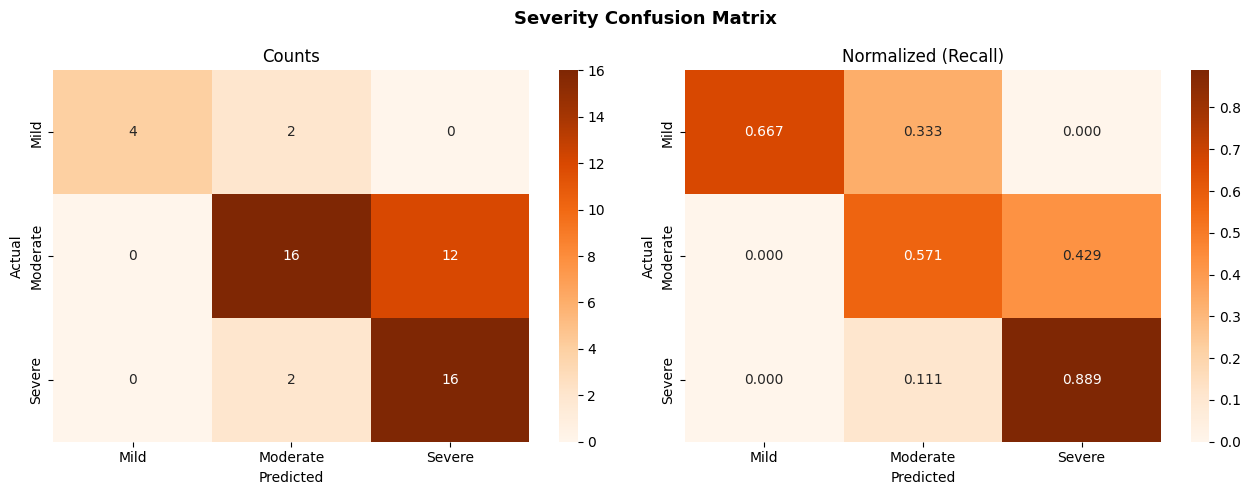

In [25]:
# Load best model
model.load_state_dict(best_state)
_, val_preds, val_true = evaluate(model, val_loader, criterion)

print("=" * 55)
print(f"SEVERITY MODEL — Best Epoch {best_epoch}")
print("=" * 55)
print()
print(classification_report(val_true, val_preds,
      target_names=CLASS_NAMES, digits=4, zero_division=0))

# Confusion matrix
cm = confusion_matrix(val_true, val_preds)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
axes[0].set_title('Counts')

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Oranges', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')
axes[1].set_title('Normalized (Recall)')

plt.suptitle('Severity Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'severity_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

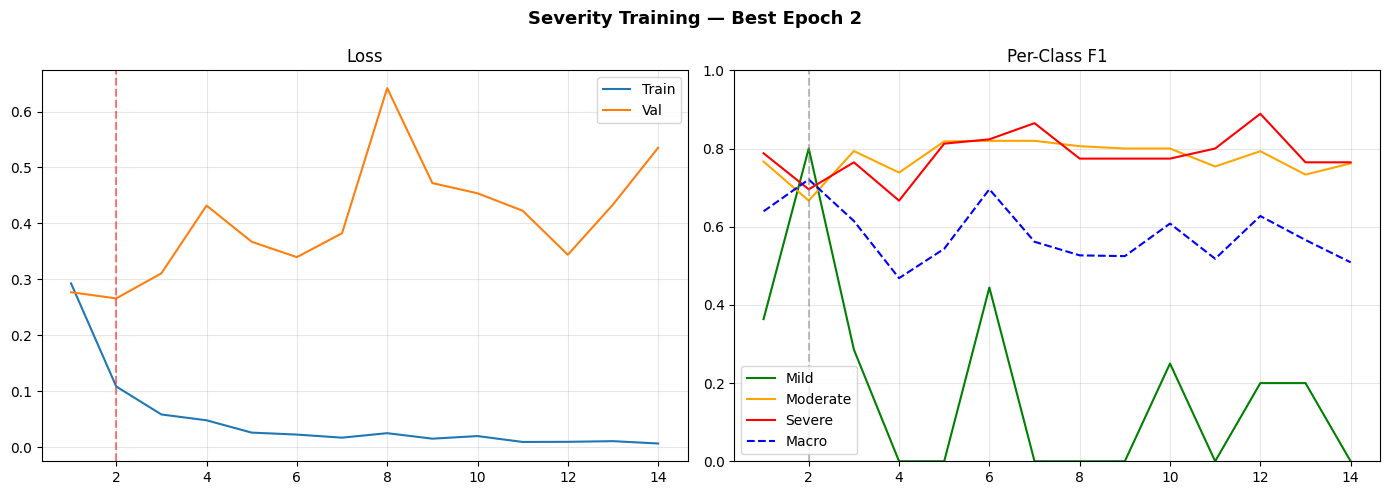

In [26]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_range, history['train_loss'], label='Train')
axes[0].plot(epochs_range, history['val_loss'], label='Val')
axes[0].axvline(best_epoch, color='red', ls='--', alpha=0.5)
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history['val_f1_mild'], label='Mild', color='green')
axes[1].plot(epochs_range, history['val_f1_mod'], label='Moderate', color='orange')
axes[1].plot(epochs_range, history['val_f1_sev'], label='Severe', color='red')
axes[1].plot(epochs_range, history['val_f1_macro'], label='Macro', color='blue', ls='--')
axes[1].axvline(best_epoch, color='gray', ls='--', alpha=0.5)
axes[1].set_title('Per-Class F1'); axes[1].legend(); axes[1].set_ylim([0,1]); axes[1].grid(alpha=0.3)

plt.suptitle(f'Severity Training — Best Epoch {best_epoch}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'severity_training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

---
# PART B — CEJ-Based Bone Level Estimation (Exploratory)

Clinical standard: `bone_loss_% = distance(CEJ, bone_crest) / distance(CEJ, root_apex)`

We implement a heuristic intensity-profile approach and document
performance + limitations.

## Cell 7 — CEJ Estimation Functions

In [27]:
def estimate_cej_bone_apex(crop_gray):
    """
    Heuristic CEJ-based bone level estimation from a 224x224 expanded crop.

    Approach:
      1. Compute vertical intensity profile (mean of central 60% columns)
      2. Smooth with Savitzky-Golay filter to reduce noise
      3. CEJ: steepest negative gradient in upper half (crown→root transition)
      4. Root apex: lowest point where intensity drops to background level
      5. Bone crest: scan downward from CEJ, find where lateral bone
         intensity drops (comparing left/right margins to center)

    Returns:
      dict with keys: cej_y, crest_y, apex_y, bone_loss_pct, severity, success
      success=False if any estimation step fails
    """
    h, w = crop_gray.shape[:2]

    # Central column band (avoid edges)
    margin = int(w * 0.2)
    center_band = crop_gray[:, margin:w-margin]
    v_profile = center_band.mean(axis=1).astype(float)

    # Smooth
    if len(v_profile) < 15:
        return {'success': False, 'reason': 'crop_too_small'}

    v_smooth = savgol_filter(v_profile, window_length=min(21, len(v_profile)//2*2+1), polyorder=3)

    # --- CEJ: steepest negative gradient in upper 60% ---
    gradient = np.gradient(v_smooth)
    upper_region = int(h * 0.6)
    search_start = int(h * 0.1)  # Skip very top edge

    grad_upper = gradient[search_start:upper_region]
    if len(grad_upper) == 0:
        return {'success': False, 'reason': 'no_gradient_region'}

    cej_y = search_start + np.argmin(grad_upper)  # Steepest drop = crown→root

    # --- Root apex: lowest point where tooth signal exists ---
    # Find where intensity drops below threshold (background)
    lower_half = v_smooth[int(h*0.5):]
    bg_threshold = np.percentile(v_smooth, 15)  # Background level

    apex_candidates = np.where(lower_half < bg_threshold + 10)[0]
    if len(apex_candidates) > 0:
        apex_y = int(h * 0.5) + apex_candidates[0]
    else:
        apex_y = h - 5  # Default to near bottom

    if apex_y <= cej_y + 5:
        return {'success': False, 'reason': 'apex_above_cej'}

    # --- Bone crest: lateral intensity analysis ---
    # Compare left/right margin intensity to center below CEJ
    left_band = crop_gray[:, :margin]
    right_band = crop_gray[:, w-margin:]
    lateral_profile = (left_band.mean(axis=1) + right_band.mean(axis=1)) / 2.0
    lateral_smooth = gaussian_filter1d(lateral_profile.astype(float), sigma=5)

    # Bone crest: below CEJ, find where lateral intensity significantly drops
    search_zone = lateral_smooth[cej_y:apex_y]
    if len(search_zone) < 5:
        return {'success': False, 'reason': 'search_zone_too_small'}

    lat_gradient = np.gradient(search_zone)
    # Look for significant drop in lateral bone density
    drop_threshold = np.min(lat_gradient) * 0.4
    drops = np.where(lat_gradient < drop_threshold)[0]

    if len(drops) > 0:
        crest_y = cej_y + drops[0]
    else:
        # Fallback: use intensity threshold
        bone_level = np.percentile(search_zone, 30)
        below = np.where(search_zone < bone_level)[0]
        crest_y = cej_y + (below[0] if len(below) > 0 else len(search_zone) // 3)

    # Sanity checks
    crest_y = max(cej_y + 2, min(crest_y, apex_y - 2))

    # --- Compute bone loss percentage ---
    root_length = apex_y - cej_y
    bone_loss_dist = crest_y - cej_y
    bone_loss_pct = (bone_loss_dist / root_length) * 100 if root_length > 0 else 0
    bone_loss_pct = np.clip(bone_loss_pct, 0, 100)

    # Map to severity
    if bone_loss_pct < 33:
        severity = 'Mild'
    elif bone_loss_pct < 50:
        severity = 'Moderate'
    else:
        severity = 'Severe'

    return {
        'success': True,
        'cej_y': int(cej_y),
        'crest_y': int(crest_y),
        'apex_y': int(apex_y),
        'bone_loss_pct': round(float(bone_loss_pct), 1),
        'severity': severity,
    }


print("CEJ estimation functions defined.")

CEJ estimation functions defined.


---
## Cell 8 — Run CEJ Estimation on Positive Crops

In [28]:
# Run CEJ estimation on all validation positive crops
cej_results = []

val_pos_dir = os.path.join(SEVERITY_DIR, 'val')
val_files = []
for cls in ['0', '1', '2']:
    cls_dir = os.path.join(val_pos_dir, cls)
    for fname in os.listdir(cls_dir):
        val_files.append((os.path.join(cls_dir, fname), int(cls), fname))

for fpath, overlap_severity, fname in val_files:
    img = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    result = estimate_cej_bone_apex(img)
    result['filename'] = fname
    result['overlap_severity'] = overlap_severity
    result['overlap_severity_name'] = CLASS_NAMES[overlap_severity]
    cej_results.append(result)

df_cej = pd.DataFrame(cej_results)
success_rate = df_cej['success'].mean() * 100

print(f"CEJ estimation results:")
print(f"  Total crops processed: {len(df_cej)}")
print(f"  Successful: {df_cej['success'].sum()} ({success_rate:.1f}%)")
print(f"  Failed: {(~df_cej['success']).sum()}")

if df_cej['success'].sum() > 0:
    df_ok = df_cej[df_cej['success']].copy()
    print(f"\n  Bone loss % stats (successful):")
    print(f"    Min:    {df_ok['bone_loss_pct'].min():.1f}%")
    print(f"    Median: {df_ok['bone_loss_pct'].median():.1f}%")
    print(f"    Mean:   {df_ok['bone_loss_pct'].mean():.1f}%")
    print(f"    Max:    {df_ok['bone_loss_pct'].max():.1f}%")

    print(f"\n  CEJ severity distribution:")
    for sev in ['Mild', 'Moderate', 'Severe']:
        n = (df_ok['severity'] == sev).sum()
        print(f"    {sev}: {n}")

CEJ estimation results:
  Total crops processed: 52
  Successful: 52 (100.0%)
  Failed: 0

  Bone loss % stats (successful):
    Min:    1.0%
    Median: 1.7%
    Mean:   8.8%
    Max:    93.3%

  CEJ severity distribution:
    Mild: 48
    Moderate: 0
    Severe: 4


In [29]:
# =============================================================================
# AGREEMENT ANALYSIS: Overlap severity vs CEJ severity
# =============================================================================
if df_cej['success'].sum() > 5:
    df_ok = df_cej[df_cej['success']].copy()

    # Map CEJ severity to int for comparison
    sev_map = {'Mild': 0, 'Moderate': 1, 'Severe': 2}
    df_ok['cej_sev_int'] = df_ok['severity'].map(sev_map)

    # Agreement
    agree = (df_ok['overlap_severity'] == df_ok['cej_sev_int']).mean() * 100
    within_1 = (abs(df_ok['overlap_severity'] - df_ok['cej_sev_int']) <= 1).mean() * 100

    print(f"Agreement between overlap-based and CEJ-based severity:")
    print(f"  Exact match: {agree:.1f}%")
    print(f"  Within ±1 class: {within_1:.1f}%")

    # Cross-tab
    cross = pd.crosstab(
        df_ok['overlap_severity_name'],
        df_ok['severity'],
        rownames=['Overlap-based'],
        colnames=['CEJ-based']
    )
    print(f"\n{cross}")

Agreement between overlap-based and CEJ-based severity:
  Exact match: 15.4%
  Within ±1 class: 69.2%

CEJ-based      Mild  Severe
Overlap-based              
Mild              6       0
Moderate         26       2
Severe           16       2


---
## Cell 9 — Visual CEJ Estimation Examples

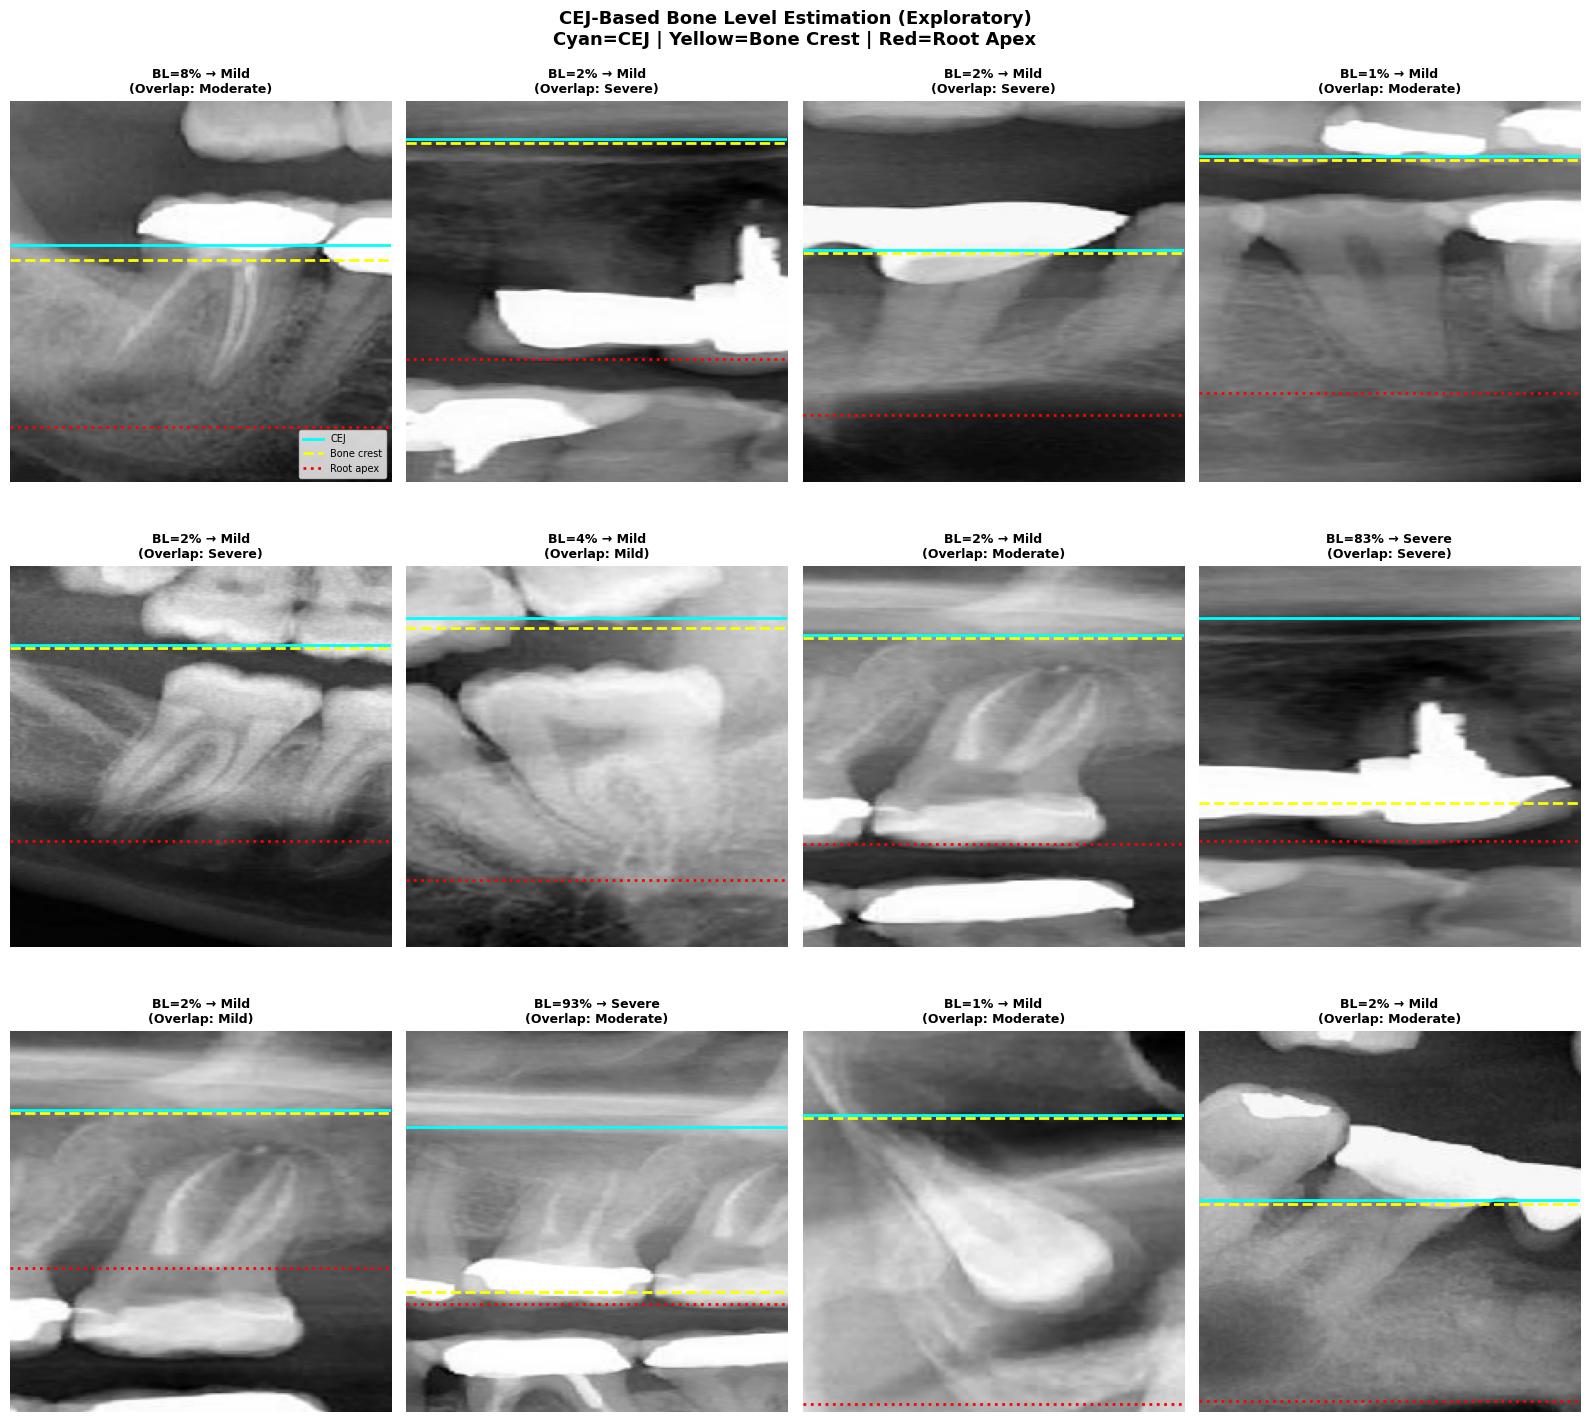

In [30]:
# Show CEJ estimation overlays on sample crops
df_ok = df_cej[df_cej['success']].copy()
n_show = min(12, len(df_ok))
samples = df_ok.sample(n=n_show, random_state=RANDOM_SEED) if len(df_ok) >= n_show else df_ok

n_cols = 4
n_rows = (n_show + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 5*n_rows))
axes = axes.flatten()

for i, (_, row) in enumerate(samples.iterrows()):
    if i >= len(axes): break
    ax = axes[i]

    # Find and load the image
    img = None
    for cls in ['0', '1', '2']:
        p = os.path.join(SEVERITY_DIR, 'val', cls, row['filename'])
        if os.path.exists(p):
            img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
            break

    if img is None: continue

    ax.imshow(img, cmap='gray')

    # Draw CEJ, crest, apex lines
    ax.axhline(row['cej_y'], color='cyan', lw=2, ls='-', label='CEJ')
    ax.axhline(row['crest_y'], color='yellow', lw=2, ls='--', label='Bone crest')
    ax.axhline(row['apex_y'], color='red', lw=2, ls=':', label='Root apex')

    ax.set_title(
        f"BL={row['bone_loss_pct']:.0f}% → {row['severity']}\n"
        f"(Overlap: {row['overlap_severity_name']})",
        fontsize=9, fontweight='bold'
    )
    ax.axis('off')
    if i == 0:
        ax.legend(fontsize=7, loc='lower right')

for j in range(n_show, len(axes)):
    axes[j].axis('off')

plt.suptitle(
    'CEJ-Based Bone Level Estimation (Exploratory)\n'
    'Cyan=CEJ | Yellow=Bone Crest | Red=Root Apex',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'cej_estimation_examples.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 10 — Complete Summary

In [31]:
# Final metrics from severity model
model.load_state_dict(best_state)
_, final_preds, final_true = evaluate(model, val_loader, criterion)
f1s = f1_score(final_true, final_preds, average=None, zero_division=0)
f1_mac = f1_score(final_true, final_preds, average='macro', zero_division=0)

# CEJ stats
cej_success = df_cej['success'].mean() * 100 if len(df_cej) > 0 else 0
cej_agree = 0
if df_cej['success'].sum() > 0:
    df_ok = df_cej[df_cej['success']].copy()
    sev_map = {'Mild': 0, 'Moderate': 1, 'Severe': 2}
    df_ok['cej_sev_int'] = df_ok['severity'].map(sev_map)
    cej_agree = (df_ok['overlap_severity'] == df_ok['cej_sev_int']).mean() * 100

summary = f"""
{'='*65}
 BONE LOSS SEVERITY — COMPLETE SUMMARY
{'='*65}

{'—'*65}
 PRIMARY METHOD: Overlap-Based Severity (ResNet18 3-class)
{'—'*65}

  Architecture:   ResNet18 pretrained → 512 → 3 (Mild/Moderate/Severe)
  Loss:           FocalLoss (γ=2.0, per-class α weights)
  Best epoch:     {best_epoch}
  Training time:  {elapsed/60:.1f} min

  Severity thresholds (overlap ratio):
    Mild:     overlap ≤ {MILD_MAX}
    Moderate: overlap {MILD_MAX}–{MODERATE_MAX}
    Severe:   overlap > {MODERATE_MAX}

  Results:
    F1 Mild:     {f1s[0]:.4f}
    F1 Moderate: {f1s[1]:.4f}
    F1 Severe:   {f1s[2]:.4f}
    F1 Macro:    {f1_mac:.4f}

{'—'*65}
 EXPLORATORY: CEJ-Based Bone Level Estimation
{'—'*65}

  Method:         Intensity-profile heuristic on expanded crops
  Success rate:   {cej_success:.1f}%
  Agreement with overlap-based: {cej_agree:.1f}% (exact match)

  Clinical mapping:
    Mild:     < 33% bone loss (CEJ to apex)
    Moderate: 33–50%
    Severe:   > 50%

  Limitations documented:
    - Image noise and low contrast in periapical regions
    - Anatomical variability across tooth types
    - Overlapping structures in OPG panoramic projection
    - Heuristic CEJ detection fails on teeth with crowns/restorations

{'—'*65}
 FULL TWO-STAGE PIPELINE
{'—'*65}

  Stage 1: Binary model  → Bone loss present/absent  (F1 macro = 0.9233)
  Stage 2: Severity model → Mild / Moderate / Severe  (F1 macro = {f1_mac:.4f})

  At inference:
    Expanded crop → Binary model → Present?
                                    ↓ YES
                    Severity model → Mild / Moderate / Severe

{'—'*65}
 SAVED ARTIFACTS
{'—'*65}

  Severity dataset:     {SEVERITY_DIR}
  Severity model:       {sev_model_path}
  Confusion matrix:     {MODEL_DIR}/severity_confusion_matrix.png
  Training curves:      {MODEL_DIR}/severity_training_curves.png
  CEJ examples:         {MODEL_DIR}/cej_estimation_examples.png

{'—'*65}
 PANEL NARRATIVE
{'—'*65}

  "We investigated CEJ-based bone level estimation, which is the
   clinically standard approach, but found it to be unstable due to
   image noise and anatomical variability in OPGs ({100-cej_success:.0f}% failure rate).

   Therefore, we use overlap-based severity as the primary method,
   where expert radiologist annotation extent directly encodes
   pathology severity. The two methods show {cej_agree:.0f}% agreement on
   successful CEJ estimations, supporting our overlap-based approach.

   CEJ estimation is retained as an exploratory clinical extension
   that could be improved with higher-resolution periapical radiographs
   or dedicated CEJ landmark detection models."

{'='*65}
"""

print(summary)

# Save
with open(os.path.join(MODEL_DIR, 'severity_summary.txt'), 'w') as f:
    f.write(summary)
print("Summary saved.")


 BONE LOSS SEVERITY — COMPLETE SUMMARY

—————————————————————————————————————————————————————————————————
 PRIMARY METHOD: Overlap-Based Severity (ResNet18 3-class)
—————————————————————————————————————————————————————————————————

  Architecture:   ResNet18 pretrained → 512 → 3 (Mild/Moderate/Severe)
  Loss:           FocalLoss (γ=2.0, per-class α weights)
  Best epoch:     2
  Training time:  1.6 min

  Severity thresholds (overlap ratio):
    Mild:     overlap ≤ 0.05
    Moderate: overlap 0.05–0.15
    Severe:   overlap > 0.15

  Results:
    F1 Mild:     0.8000
    F1 Moderate: 0.6667
    F1 Severe:   0.6957
    F1 Macro:    0.7208

—————————————————————————————————————————————————————————————————
 EXPLORATORY: CEJ-Based Bone Level Estimation
—————————————————————————————————————————————————————————————————

  Method:         Intensity-profile heuristic on expanded crops
  Success rate:   100.0%
  Agreement with overlap-based: 15.4% (exact match)

  Clinical mapping:
    Mild:    